# inspect reactome + and merge with kegg

In [1]:
import requests
import pandas as pd
import time
import os
import pickle

# ============================================================================
# 1. DOWNLOAD REACTOME INTERACTIONS FILE
# ============================================================================

def download_interactions_file(output_file='reactome_interactions_human.txt'):
    """
    Download human protein-protein interactions from Reactome
    """
    print("Downloading Reactome human protein-protein interactions...")
    
    url =  'https://download.reactome.org/96/interactors/reactome.homo_sapiens.interactions.tab-delimited.txt'

    
    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        
        # Save to file
        with open(output_file, 'w') as f:
            f.write(response.text)
        
        # Parse into dataframe
        df = pd.read_csv(output_file, sep='\t')
        print(f"✓ Downloaded interactions file")
        print(f"  Shape: {df.shape}")
        print(f"  Columns: {df.columns.tolist()}\n")
        
        return df
    
    except Exception as e:
        print(f"✗ Error: {e}")
        return None


# ============================================================================
# 2. DOWNLOAD PATHWAY MAPPING FILES
# ============================================================================

def download_uniprot_to_pathways(output_file='uniprot_to_pathways.txt'):
    """
    Download UniProt to Pathways mapping (all levels)
    """
    print("Downloading UniProt to Pathways mapping...")
    
    url = 'https://download.reactome.org/96/UniProt2Reactome_All_Levels.txt'
    
    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        
        with open(output_file, 'w') as f:
            f.write(response.text)
        
        df = pd.read_csv(output_file, sep='\t', header=None)
        df.columns = ['uniprot_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']
        
        print(f"✓ Downloaded UniProt to Pathways mapping")
        print(f"  Shape: {df.shape}")
        print(f"  Columns: {df.columns.tolist()}\n")
        
        return df
    
    except Exception as e:
        print(f"✗ Error: {e}")
        return None


def download_ensembl_to_pathways(output_file='ensembl_to_pathways.txt'):
    """
    Download ENSEMBL to Pathways mapping (all levels)
    """
    print("Downloading ENSEMBL to Pathways mapping...")
    
    url = 'https://download.reactome.org/96/Ensembl2Reactome_All_Levels.txt'
    
    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        
        with open(output_file, 'w') as f:
            f.write(response.text)
        
        df = pd.read_csv(output_file, sep='\t', header=None)
        df.columns = ['ensembl_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']
        
        print(f"✓ Downloaded ENSEMBL to Pathways mapping")
        print(f"  Shape: {df.shape}")
        print(f"  Columns: {df.columns.tolist()}\n")
        
        return df
    
    except Exception as e:
        print(f"✗ Error: {e}")
        return None


def download_ncbi_to_pathways(output_file='ncbi_to_pathways.txt'):
    """
    Download NCBI Gene ID to Pathways mapping (all levels)
    """
    print("Downloading NCBI Gene ID to Pathways mapping...")
    
    url = 'https://download.reactome.org/96/NCBI2Reactome_All_Levels.txt'
    
    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        
        with open(output_file, 'w') as f:
            f.write(response.text)
        
        df = pd.read_csv(output_file, sep='\t', header=None)
        df.columns = ['ncbi_gene_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']
        
        print(f"✓ Downloaded NCBI Gene ID to Pathways mapping")
        print(f"  Shape: {df.shape}")
        print(f"  Columns: {df.columns.tolist()}\n")
        
        return df
    
    except Exception as e:
        print(f"✗ Error: {e}")
        return None


# ============================================================================
# 3. DOWNLOAD PATHWAY INFORMATION
# ============================================================================

# Fix the pathway hierarchy download function
def download_pathway_hierarchy(output_file='pathway_hierarchy.txt'):
    """
    Download pathway hierarchy information
    """
    print("Downloading pathway hierarchy...")
    
    url = 'https://download.reactome.org/96/ReactomePathwaysRelation.txt'
    
    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        
        with open(output_file, 'w') as f:
            f.write(response.text)
        
        # Read without assigning column names first
        df = pd.read_csv(output_file, sep='\t', header=None)
        
        # Assign correct number of columns based on actual data
        if df.shape[1] == 4:
            df.columns = ['parent_pathway_id', 'parent_pathway_name', 'child_pathway_id', 'child_pathway_name']
        elif df.shape[1] == 2:
            df.columns = ['parent_pathway_id', 'child_pathway_id']
        
        print(f"✓ Downloaded pathway hierarchy")
        print(f"  Shape: {df.shape}\n")
        
        return df
    
    except Exception as e:
        print(f"✗ Error: {e}")
        return None

print("Fixed function ready to use!")


def download_pathway_list(output_file='pathway_list.txt'):
    """
    Download complete list of pathways
    """
    print("Downloading complete pathway list...")
    
    url = 'https://download.reactome.org/96/ReactomePathways.txt'
    
    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        
        with open(output_file, 'w') as f:
            f.write(response.text)
        
        df = pd.read_csv(output_file, sep='\t', header=None)
        df.columns = ['reactome_id', 'pathway_name', 'species']
        
        print(f"✓ Downloaded pathway list")
        print(f"  Shape: {df.shape}")
        print(f"  Unique species: {df['species'].nunique()}\n")
        
        return df
    
    except Exception as e:
        print(f"✗ Error: {e}")
        return None

# ============================================================================
# 4. MERGE INTERACTIONS WITH PATHWAY INFORMATION  (updated)
# ============================================================================

def merge_interactions_with_pathways(
    interactions_df,
    uniprot_pathways_df,
    kegg_pathways_df=None,       # NEW: optional KEGG dataframe
    multiplex_proteins=None
):
    """
    Merge interactions with pathway information.
    Tags each pathway with its source (Reactome / KEGG / both).

    Expected KEGG dataframe columns: ['uniprot_id', 'pathway_name']
    (add a 'source' column yourself if you build it from KEGG API data)
    """
    print("Merging interactions with pathway information...")

    # ── 1. Tag sources ───────────────────────────────────────────────────────
    reactome = uniprot_pathways_df[['uniprot_id', 'pathway_name']].copy()
    reactome['source'] = 'Reactome'

    if kegg_pathways_df is not None:
        kegg = kegg_pathways_df[['gene_name_uniprot', 'pathway_name']].copy()
        kegg['source'] = 'KEGG'
        kegg = kegg.rename(columns={'gene_name_uniprot': 'uniprot_id'})
        all_pathways = pd.concat([reactome, kegg], ignore_index=True)
    else:
        all_pathways = reactome

    # ── 2. Optionally filter to multiplex proteins ───────────────────────────
    if multiplex_proteins is not None:
        print(f"  Filtering to {len(multiplex_proteins):,} multiplex proteins...")

        interactions_df = interactions_df[
            interactions_df['# Interactor 1 uniprot id'].str.replace('uniprotkb:', '').isin(multiplex_proteins) &
            interactions_df['Interactor 2 uniprot id'].str.replace('uniprotkb:', '').isin(multiplex_proteins)
        ].copy()
        print(f"  Interactions after filter: {len(interactions_df):,}")

        all_pathways = all_pathways[
            all_pathways['uniprot_id'].isin(multiplex_proteins)
        ].copy()
        print(f"  Pathway mappings after filter: {len(all_pathways):,}")

    # ── 3. Clean UniProt IDs ─────────────────────────────────────────────────
    interactions_df['uniprot1'] = interactions_df['# Interactor 1 uniprot id'].str.replace('uniprotkb:', '')
    interactions_df['uniprot2'] = interactions_df['Interactor 2 uniprot id'].str.replace('uniprotkb:', '')

    # ── 4. Collapse multiple pathways/sources per protein into one row ────────
    # So the merge doesn't explode row count unexpectedly
    def collapse(df, id_col):
        return (
            df.groupby(id_col)
            .agg(
                pathway_names=('pathway_name', lambda x: '|'.join(sorted(set(x)))),
                sources=('source',        lambda x: '|'.join(sorted(set(x))))
            )
            .reset_index()
        )

    collapsed = collapse(all_pathways, 'uniprot_id')

    # ── 5. Merge for protein 1 ───────────────────────────────────────────────
    merged = interactions_df.merge(
        collapsed.rename(columns={
            'uniprot_id':     'uniprot_id_1',
            'pathway_names':  'pathway_protein1',
            'sources':        'source_protein1'
        }),
        left_on='uniprot1', right_on='uniprot_id_1', how='left'
    ).drop(columns='uniprot_id_1')

    # ── 6. Merge for protein 2 ───────────────────────────────────────────────
    merged = merged.merge(
        collapsed.rename(columns={
            'uniprot_id':     'uniprot_id_2',
            'pathway_names':  'pathway_protein2',
            'sources':        'source_protein2'
        }),
        left_on='uniprot2', right_on='uniprot_id_2', how='left'
    ).drop(columns='uniprot_id_2')

    # ── 7. Common pathway + combined source label ────────────────────────────
    def find_common_pathway(row):
        p1 = set(row['pathway_protein1'].split('|')) if pd.notna(row['pathway_protein1']) else set()
        p2 = set(row['pathway_protein2'].split('|')) if pd.notna(row['pathway_protein2']) else set()
        common = p1 & p2
        return '|'.join(sorted(common)) if common else None

    def combined_sources(row):
        s1 = set(row['source_protein1'].split('|')) if pd.notna(row['source_protein1']) else set()
        s2 = set(row['source_protein2'].split('|')) if pd.notna(row['source_protein2']) else set()
        combined = s1 | s2
        return '|'.join(sorted(combined)) if combined else None

    merged['common_pathway']  = merged.apply(find_common_pathway,  axis=1)
    merged['pathway_sources'] = merged.apply(combined_sources,      axis=1)

    # ── 8. Summary ───────────────────────────────────────────────────────────
    print(f"✓ Merged {len(merged):,} interactions with pathway information")
    print(f"  Interactions with common pathway: {merged['common_pathway'].notna().sum():,}")
    if kegg_pathways_df is not None:
        src_counts = merged['pathway_sources'].value_counts(dropna=False)
        print(f"\n  Source breakdown (pathway_sources column):")
        for src, cnt in src_counts.items():
            print(f"    {src}: {cnt:,}")
    print()

    return merged

Fixed function ready to use!


In [2]:
print("="*70)
print("REACTOME DATA DOWNLOAD")
print("="*70 + "\n")

# Step 1: Download interactions
print("STEP 1: Download Protein-Protein Interactions")
print("-"*70)
interactions_df = download_interactions_file()

# Step 2: Download pathway mappings
print("STEP 2: Download Pathway Mappings")
print("-"*70)
uniprot_pathways_df = download_uniprot_to_pathways()
ensembl_pathways_df = download_ensembl_to_pathways()
ncbi_pathways_df = download_ncbi_to_pathways()

# Step 3: Download pathway information
print("STEP 3: Download Pathway Information")
print("-"*70)
pathway_list_df = download_pathway_list()
pathway_hierarchy_df = download_pathway_hierarchy()



REACTOME DATA DOWNLOAD

STEP 1: Download Protein-Protein Interactions
----------------------------------------------------------------------
✓ Downloaded interactions file
  Shape: (123895, 9)
  Columns: ['# Interactor 1 uniprot id', 'Interactor 1 Ensembl gene id', 'Interactor 1 Entrez Gene id', 'Interactor 2 uniprot id', 'Interactor 2 Ensembl gene id', 'Interactor 2 Entrez Gene id', 'Interaction type', 'Interaction context', 'Pubmed references']

STEP 2: Download Pathway Mappings
----------------------------------------------------------------------
✓ Downloaded UniProt to Pathways mapping
  Shape: (934947, 6)
  Columns: ['uniprot_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']

✓ Downloaded ENSEMBL to Pathways mapping
  Shape: (3656157, 6)
  Columns: ['ensembl_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']



/tmp/ipykernel_737433/2663070390.py:118: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(output_file, sep='\t', header=None)


✓ Downloaded NCBI Gene ID to Pathways mapping
  Shape: (780042, 6)
  Columns: ['ncbi_gene_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']

STEP 3: Download Pathway Information
----------------------------------------------------------------------
✓ Downloaded pathway list
  Shape: (23498, 3)
  Unique species: 16

✓ Downloaded pathway hierarchy
  Shape: (23612, 2)



In [3]:
import pandas as pd
import pickle
import os
import networkx as nx

def load_layers_from_folder(layers_dir):
    """Load all *_layer.pkl files from a folder."""
    layers = {}
    pkl_files = [f for f in os.listdir(layers_dir) if f.endswith('_layer.pkl')]
    
    if not pkl_files:
        raise FileNotFoundError(f"No *_layer.pkl files found in {layers_dir}")
    
    print(f"Found {len(pkl_files)} layer files")
    
    for fname in sorted(pkl_files):
        cell_type = fname.replace('_layer.pkl', '')
        fpath = os.path.join(layers_dir, fname)
        with open(fpath, 'rb') as f:
            layers[cell_type] = pickle.load(f)
    
    print(f"✓ Loaded {len(layers)} layers\n")
    return layers


def convert_layer_nodes_to_uniprot(layers, uniprot_to_symbol):
    """
    Convert all node labels in layers from gene symbols to UniProt IDs.
    
    Parameters
    ----------
    layers : dict of cell_type -> nx.Graph (nodes are gene symbols)
    uniprot_to_symbol : dict mapping uniprot_id -> gene_symbol
    
    Returns
    -------
    converted_layers : dict of cell_type -> nx.Graph (nodes are uniprot IDs)
    unmapped_genes : set of genes that couldn't be mapped
    """
    
    # Reverse the mapping: symbol -> uniprot
    symbol_to_uniprot = {v.upper(): k for k, v in uniprot_to_symbol.items()}
    
    converted_layers = {}
    unmapped_genes = set()
    total_mapped = 0
    
    for cell_type, layer in layers.items():
        node_mapping = {}
        for node in layer.nodes():
            symbol_upper = str(node).upper()
            if symbol_upper in symbol_to_uniprot:
                node_mapping[node] = symbol_to_uniprot[symbol_upper]
                total_mapped += 1
            else:
                unmapped_genes.add(node)
                node_mapping[node] = node  # keep original if not found
        
        converted_layer = nx.relabel_nodes(layer, node_mapping)
        converted_layers[cell_type] = converted_layer
        
        n_mapped = sum(1 for v in node_mapping.values() if v in symbol_to_uniprot.values())
        print(f"  {cell_type}: {len(node_mapping)} nodes → {n_mapped} mapped to UniProt")
    
    if unmapped_genes:
        print(f"\n⚠️  {len(unmapped_genes)} genes could not be mapped:")
        for gene in sorted(list(unmapped_genes)[:10]):
            print(f"    - {gene}")
        if len(unmapped_genes) > 10:
            print(f"    ... and {len(unmapped_genes) - 10} more")
    
    return converted_layers, unmapped_genes


def save_converted_layers(converted_layers, output_dir='layers_uniprot'):
    """Save converted layers to new folder."""
    os.makedirs(output_dir, exist_ok=True)
    
    for cell_type, layer in converted_layers.items():
        safe_name = cell_type.replace('/', '_').replace(' ', '_')
        fpath = os.path.join(output_dir, f"{safe_name}_layer.pkl")
        with open(fpath, 'wb') as f:
            pickle.dump(layer, f, protocol=4)
    
    print(f"✓ Saved {len(converted_layers)} converted layers to {output_dir}\n")
    return output_dir


def get_multiplex_proteins(converted_layers):
    """Get the set of all unique UniProt IDs across all layers."""
    proteins = set()
    for cell_type, layer in converted_layers.items():
        proteins.update(layer.nodes())
    print(f"✓ Found {len(proteins):,} unique proteins across {len(converted_layers)} layers\n")
    return proteins




In [4]:

# Step 1: Load UniProt mapping
uniprot_mapping_csv = 'ppi_chloe/d_uniprot_to_symbol_20251120.csv'

print("Loading UniProt to gene symbol mapping...")
mapping_df = pd.read_csv('../../og_gene_set/ppi_chloe/d_uniprot_to_symbol_20251120.csv')
uniprot_to_symbol = dict(zip(mapping_df['uniprotid'], mapping_df['symbol']))
print(f"✓ Loaded mapping for {len(uniprot_to_symbol):,} UniProt IDs\n")


Loading UniProt to gene symbol mapping...
✓ Loaded mapping for 165,580 UniProt IDs



In [5]:
layers_dir_1 = "../multiplex_ts/layers"
layers_dir_2 = "../multiplex_2025hdrg/layers"

layers_1 = load_layers_from_folder(layers_dir_1)
layers_2 = load_layers_from_folder(layers_dir_2)

# Merge — if same cell type exists in both, second folder wins
layers = {**layers_1, **layers_2}

print(f"Total layers: {len(layers)}")



Found 156 layer files
✓ Loaded 156 layers

Found 22 layer files
✓ Loaded 22 layers

Total layers: 178


In [19]:
layers

{'acinar_cell_of_salivary_gland': <networkx.classes.graph.Graph at 0x7f2fc6f8b8c0>,
 'adipocyte': <networkx.classes.graph.Graph at 0x7f2fcd671450>,
 'adventitial_cell': <networkx.classes.graph.Graph at 0x7f2fcd671090>,
 'alveolar_fibroblast': <networkx.classes.graph.Graph at 0x7f2fc6fd62c0>,
 'artery_endothelial_cell': <networkx.classes.graph.Graph at 0x7f2fc6fd6520>,
 'b_cell': <networkx.classes.graph.Graph at 0x7f2fc728c950>,
 'basal_cell': <networkx.classes.graph.Graph at 0x7f2fc743b790>,
 'basal_cell_of_prostate_epithelium': <networkx.classes.graph.Graph at 0x7f2fc74ad480>,
 'bladder_urothelial_cell': <networkx.classes.graph.Graph at 0x7f2fc745d650>,
 'bronchial_smooth_muscle_cell': <networkx.classes.graph.Graph at 0x7f2fc745d850>,
 'bronchial_vessel_endothelial_cell': <networkx.classes.graph.Graph at 0x7f2fc73ea4e0>,
 'capillary_endothelial_cell': <networkx.classes.graph.Graph at 0x7f2fc6f83890>,
 'cardiac_endothelial_cell': <networkx.classes.graph.Graph at 0x7f2fc8ee9c50>,
 'card

In [6]:

# Step 3: Convert to UniProt
print("Converting gene symbols → UniProt IDs...\n")
converted_layers, unmapped = convert_layer_nodes_to_uniprot(layers, uniprot_to_symbol)

# Step 4: Save converted layers
output_dir = save_converted_layers(converted_layers, output_dir='layers_uniprot')

# Step 5: Get unique proteins for filtering
multiplex_proteins = get_multiplex_proteins(converted_layers)

print("="*80)
print("CONVERSION COMPLETE")
print("="*80)
print(f"Converted layers saved to: {output_dir}")
print(f"Use 'multiplex_proteins' set in your merge script to filter interactions")

Converting gene symbols → UniProt IDs...

  acinar_cell_of_salivary_gland: 2386 nodes → 2373 mapped to UniProt
  adipocyte: 3099 nodes → 3078 mapped to UniProt
  adventitial_cell: 2763 nodes → 2745 mapped to UniProt
  alveolar_fibroblast: 1200 nodes → 1195 mapped to UniProt
  artery_endothelial_cell: 3171 nodes → 3159 mapped to UniProt
  b_cell: 1179 nodes → 1169 mapped to UniProt
  basal_cell: 3182 nodes → 3158 mapped to UniProt
  basal_cell_of_prostate_epithelium: 3035 nodes → 3004 mapped to UniProt
  bladder_urothelial_cell: 3198 nodes → 3177 mapped to UniProt
  bronchial_smooth_muscle_cell: 1412 nodes → 1403 mapped to UniProt
  bronchial_vessel_endothelial_cell: 3312 nodes → 3302 mapped to UniProt
  capillary_endothelial_cell: 1394 nodes → 1387 mapped to UniProt
  cardiac_endothelial_cell: 2065 nodes → 2058 mapped to UniProt
  cardiac_muscle_cell: 3247 nodes → 3228 mapped to UniProt
  cd141-positive_myeloid_dendritic_cell: 3296 nodes → 3277 mapped to UniProt
  cd1c-positive_myeloid

In [7]:
kegg_pathways_df = pd.read_csv("kegg_pathways_with_names_symbols.csv")
kegg_pathways_df.head()

,Unnamed: 0,gene_name,pathway_name,gene_name_uniprot,gene_name_symbol,gene_symbol
0,0,hsa:10,Metabolic pathways - Homo sapiens (human),A4Z6T7,NAT2,NAT2
1,1,hsa:100,Metabolic pathways - Homo sapiens (human),A0A0S2Z381,ADA,ADA
2,2,hsa:10005,Metabolic pathways - Homo sapiens (human),O14734,ACOT8,ACOT8
3,3,hsa:10007,Metabolic pathways - Homo sapiens (human),P46926,GNPDA1,GNPDA1
4,4,hsa:100137049,Metabolic pathways - Homo sapiens (human),P0C869,PLA2G4B,PLA2G4B


In [8]:
# ── DIAGNOSTIC: Run this BEFORE merging to understand what you have ──────────

print("=== DIAGNOSTIC ===\n")

# Check Reactome pathways
print("REACTOME:")
print(f"  Total rows: {len(uniprot_pathways_df)}")
human_reactome = uniprot_pathways_df[uniprot_pathways_df['species'] == 'Homo sapiens']
print(f"  Human-only rows: {len(human_reactome)}")
print(f"  Unique UniProt IDs: {human_reactome['uniprot_id'].nunique()}")
print(f"  Unique pathway names: {human_reactome['pathway_name'].nunique()}")
print(f"  Sample UniProt IDs: {human_reactome['uniprot_id'].head(5).tolist()}")
print()

# Check KEGG pathways
print("KEGG:")
print(f"  Total rows: {len(kegg_pathways_df)}")
print(f"  Columns: {kegg_pathways_df.columns.tolist()}")
print(f"  Unique pathway names: {kegg_pathways_df['pathway_name'].nunique()}")

# Check how many KEGG uniprot IDs are still in hsa: format (unconverted)
kegg_still_hsa = kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False).sum()
kegg_converted = (~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False)).sum()
print(f"  gene_name_uniprot - still hsa: format (failed conversion): {kegg_still_hsa}")
print(f"  gene_name_uniprot - converted to UniProt: {kegg_converted}")
print(f"  Sample gene_name_uniprot values: {kegg_pathways_df['gene_name_uniprot'].head(5).tolist()}")
print()

# Check overlap between KEGG UniProt IDs and multiplex proteins
kegg_uniprot_clean = set(
    kegg_pathways_df.loc[
        ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False),
        'gene_name_uniprot'
    ]
)
overlap_kegg_multiplex = kegg_uniprot_clean & multiplex_proteins
print(f"  KEGG UniProt IDs overlapping with multiplex_proteins: {len(overlap_kegg_multiplex)}")

# Check overlap between Reactome UniProt IDs and multiplex proteins
reactome_uniprot = set(human_reactome['uniprot_id'])
overlap_reactome_multiplex = reactome_uniprot & multiplex_proteins
print(f"  Reactome UniProt IDs overlapping with multiplex_proteins: {len(overlap_reactome_multiplex)}")
print()

# Check interaction UniProt ID format
print("INTERACTIONS:")
sample_p1 = interactions_df['# Interactor 1 uniprot id'].head(3).tolist()
sample_p2 = interactions_df['Interactor 2 uniprot id'].head(3).tolist()
print(f"  Sample Interactor 1: {sample_p1}")
print(f"  Sample Interactor 2: {sample_p2}")
# These likely have 'uniprotkb:' prefix - check it's being stripped correctly

=== DIAGNOSTIC ===

REACTOME:
  Total rows: 934947
  Human-only rows: 159114
  Unique UniProt IDs: 12136
  Unique pathway names: 2843
  Sample UniProt IDs: ['A0A075B6P5', 'A0A075B6P5', 'A0A075B6P5', 'A0A075B6P5', 'A0A075B6P5']

KEGG:
  Total rows: 39334
  Columns: ['Unnamed: 0', 'gene_name', 'pathway_name', 'gene_name_uniprot', 'gene_name_symbol', 'gene_symbol']
  Unique pathway names: 370
  gene_name_uniprot - still hsa: format (failed conversion): 1056
  gene_name_uniprot - converted to UniProt: 38278
  Sample gene_name_uniprot values: ['A4Z6T7', 'A0A0S2Z381', 'O14734', 'P46926', 'P0C869']

  KEGG UniProt IDs overlapping with multiplex_proteins: 985
  Reactome UniProt IDs overlapping with multiplex_proteins: 1218

INTERACTIONS:
  Sample Interactor 1: ['uniprotkb:Q9Y287', 'uniprotkb:P37840', 'uniprotkb:P0DJI8']
  Sample Interactor 2: ['uniprotkb:Q9Y287', 'uniprotkb:P37840', 'uniprotkb:P0DJI8']


In [9]:
def merge_interactions_with_pathways(
    interactions_df,
    uniprot_pathways_df,
    kegg_pathways_df=None,
    multiplex_proteins=None
):
    """
    Merge interactions with pathway information.
    Tags each pathway with its source (Reactome / KEGG / both).
    """
    print("Merging interactions with pathway information...")

    # ── 1. Prepare Reactome pathways ─────────────────────────────────────────
    # CRITICAL FIX: Filter to human only - the full file has all species
    # Without this, you get mouse/rat/etc UniProt IDs polluting the merge
    reactome = uniprot_pathways_df[
        uniprot_pathways_df['species'] == 'Homo sapiens'
    ][['uniprot_id', 'pathway_name']].copy()
    reactome['source'] = 'Reactome'

    print(f"  Reactome (human only): {len(reactome):,} rows, "
          f"{reactome['uniprot_id'].nunique():,} proteins, "
          f"{reactome['pathway_name'].nunique():,} pathways")

    # ── 2. Prepare KEGG pathways ─────────────────────────────────────────────
    if kegg_pathways_df is not None:
        kegg = kegg_pathways_df[['gene_name_uniprot', 'pathway_name']].copy()
        kegg = kegg.rename(columns={'gene_name_uniprot': 'uniprot_id'})
        kegg['source'] = 'KEGG'

        # CRITICAL FIX: Drop rows where UniProt conversion failed (still hsa: format)
        kegg_before = len(kegg)
        kegg = kegg[~kegg['uniprot_id'].str.startswith('hsa:', na=False)].copy()
        kegg_dropped = kegg_before - len(kegg)

        print(f"  KEGG: {len(kegg):,} rows after dropping {kegg_dropped:,} unconverted IDs, "
              f"{kegg['uniprot_id'].nunique():,} proteins, "
              f"{kegg['pathway_name'].nunique():,} pathways")

        all_pathways = pd.concat([reactome, kegg], ignore_index=True)
    else:
        all_pathways = reactome

    print(f"  Combined: {len(all_pathways):,} rows, "
          f"{all_pathways['uniprot_id'].nunique():,} unique proteins, "
          f"{all_pathways['pathway_name'].nunique():,} unique pathways")
    print()

    # ── 3. Optionally filter to multiplex proteins ───────────────────────────
    if multiplex_proteins is not None:
        print(f"  Filtering to {len(multiplex_proteins):,} multiplex proteins...")

        # Strip uniprotkb: prefix from interactions before filtering
        p1_clean = interactions_df['# Interactor 1 uniprot id'].str.replace('uniprotkb:', '', regex=False)
        p2_clean = interactions_df['Interactor 2 uniprot id'].str.replace('uniprotkb:', '', regex=False)

        mask = p1_clean.isin(multiplex_proteins) & p2_clean.isin(multiplex_proteins)
        interactions_df = interactions_df[mask].copy()
        print(f"  Interactions after filter: {len(interactions_df):,}")

        all_pathways = all_pathways[
            all_pathways['uniprot_id'].isin(multiplex_proteins)
        ].copy()
        print(f"  Pathway mappings after filter: {len(all_pathways):,}")
        print(f"  Unique pathways after filter: {all_pathways['pathway_name'].nunique():,}")
        print()

    # ── 4. Clean UniProt IDs in interactions ─────────────────────────────────
    interactions_df = interactions_df.copy()
    interactions_df['uniprot1'] = (
        interactions_df['# Interactor 1 uniprot id']
        .str.replace('uniprotkb:', '', regex=False)
    )
    interactions_df['uniprot2'] = (
        interactions_df['Interactor 2 uniprot id']
        .str.replace('uniprotkb:', '', regex=False)
    )

    # ── 5. Collapse pathways per protein ─────────────────────────────────────
    # Separate by source first so we can track which source each pathway came from
    def collapse(df, id_col):
        return (
            df.groupby(id_col)
            .agg(
                pathway_names=('pathway_name', lambda x: '|'.join(sorted(set(x)))),
                sources=('source', lambda x: '|'.join(sorted(set(x))))
            )
            .reset_index()
        )

    collapsed = collapse(all_pathways, 'uniprot_id')
    print(f"  Collapsed to {len(collapsed):,} unique proteins with pathway info")

    # ── 6. Merge for protein 1 ───────────────────────────────────────────────
    merged = interactions_df.merge(
        collapsed.rename(columns={
            'uniprot_id':    'uniprot_id_1',
            'pathway_names': 'pathway_protein1',
            'sources':       'source_protein1'
        }),
        left_on='uniprot1', right_on='uniprot_id_1', how='left'
    ).drop(columns='uniprot_id_1')

    # ── 7. Merge for protein 2 ───────────────────────────────────────────────
    merged = merged.merge(
        collapsed.rename(columns={
            'uniprot_id':    'uniprot_id_2',
            'pathway_names': 'pathway_protein2',
            'sources':       'source_protein2'
        }),
        left_on='uniprot2', right_on='uniprot_id_2', how='left'
    ).drop(columns='uniprot_id_2')

    # ── 8. Common pathways + source labeling ─────────────────────────────────
    def find_common_pathways(row):
        p1 = set(row['pathway_protein1'].split('|')) if pd.notna(row['pathway_protein1']) else set()
        p2 = set(row['pathway_protein2'].split('|')) if pd.notna(row['pathway_protein2']) else set()
        common = p1 & p2
        return '|'.join(sorted(common)) if common else None

    def combined_sources(row):
        s1 = set(row['source_protein1'].split('|')) if pd.notna(row['source_protein1']) else set()
        s2 = set(row['source_protein2'].split('|')) if pd.notna(row['source_protein2']) else set()
        combined = s1 | s2
        return '|'.join(sorted(combined)) if combined else None

    merged['common_pathway']  = merged.apply(find_common_pathways, axis=1)
    merged['pathway_sources'] = merged.apply(combined_sources,      axis=1)

    # ── 9. Summary ───────────────────────────────────────────────────────────
    n_with_pathway = merged['common_pathway'].notna().sum()
    n_total        = len(merged)

    print(f"✓ Merged {n_total:,} interactions with pathway information")
    print(f"  Interactions with ≥1 common pathway: {n_with_pathway:,} "
          f"({100*n_with_pathway//n_total if n_total else 0}%)")

    # Count unique pathway names actually used
    all_common = merged['common_pathway'].dropna()
    if len(all_common) > 0:
        unique_pathways_used = set('|'.join(all_common).split('|'))
        print(f"  Unique pathway names in common_pathway column: {len(unique_pathways_used):,}")

    if kegg_pathways_df is not None:
        print(f"\n  Source breakdown (pathway_sources column):")
        src_counts = merged['pathway_sources'].value_counts(dropna=False)
        for src, cnt in src_counts.items():
            print(f"    {src}: {cnt:,}")

    # Check proteins with no pathway info at all
    no_p1 = merged['pathway_protein1'].isna().sum()
    no_p2 = merged['pathway_protein2'].isna().sum()
    print(f"\n  Proteins with no pathway info - Interactor 1: {no_p1:,}, Interactor 2: {no_p2:,}")
    print()

    return merged

In [10]:
# Step 4: Merge and create combined dataset

if interactions_df is not None and uniprot_pathways_df is not None:
    print("STEP 4: Merge Interactions with Pathway Information")
    print("-"*70)
    merged_df = merge_interactions_with_pathways(
        interactions_df,
        uniprot_pathways_df,
        kegg_pathways_df,
        multiplex_proteins=multiplex_proteins
    )


    # Save merged data
    merged_df.to_csv('reactome_interactions_with_pathways.csv', index=False)
    print(f"✓ Saved to reactome_interactions_with_pathways.csv\n")

# Summary
print("="*70)
print("SUMMARY")
print("="*70)
print(f"✓ Downloaded files:")
print(f"  - reactome_interactions_human.txt ({interactions_df.shape[0] if interactions_df is not None else 0} interactions)")
print(f"  - uniprot_to_pathways.txt ({uniprot_pathways_df.shape[0] if uniprot_pathways_df is not None else 0} mappings)")
print(f"  - ensembl_to_pathways.txt ({ensembl_pathways_df.shape[0] if ensembl_pathways_df is not None else 0} mappings)")
print(f"  - ncbi_to_pathways.txt ({ncbi_pathways_df.shape[0] if ncbi_pathways_df is not None else 0} mappings)")
print(f"  - pathway_list.txt ({pathway_list_df.shape[0] if pathway_list_df is not None else 0} pathways)")
print(f"  - pathway_hierarchy.txt ({pathway_hierarchy_df.shape[0] if pathway_hierarchy_df is not None else 0} relationships)")
print(f"  - reactome_interactions_with_pathways.csv (merged data)")

STEP 4: Merge Interactions with Pathway Information
----------------------------------------------------------------------
Merging interactions with pathway information...
  Reactome (human only): 159,114 rows, 12,136 proteins, 2,843 pathways
  KEGG: 38,278 rows after dropping 1,056 unconverted IDs, 8,427 proteins, 370 pathways
  Combined: 197,392 rows, 15,590 unique proteins, 3,213 unique pathways

  Filtering to 14,874 multiplex proteins...
  Interactions after filter: 858
  Pathway mappings after filter: 18,140
  Unique pathways after filter: 2,138

  Collapsed to 1,566 unique proteins with pathway info
✓ Merged 858 interactions with pathway information
  Interactions with ≥1 common pathway: 854 (99%)
  Unique pathway names in common_pathway column: 1,248

  Source breakdown (pathway_sources column):
    KEGG|Reactome: 661
    Reactome: 195
    KEGG: 2

  Proteins with no pathway info - Interactor 1: 0, Interactor 2: 0

✓ Saved to reactome_interactions_with_pathways.csv

SUMMARY
✓ D

In [11]:
# ── DEEPER DIAGNOSTIC ────────────────────────────────────────────────────────

print("=== COVERAGE ANALYSIS ===\n")

print(f"Total multiplex proteins: {len(multiplex_proteins):,}")

# What format are multiplex proteins in?
sample_mp = list(multiplex_proteins)[:10]
print(f"Sample multiplex proteins: {sample_mp}\n")

# ── Reactome coverage ────────────────────────────────────────────────────────
human_reactome = uniprot_pathways_df[uniprot_pathways_df['species'] == 'Homo sapiens']
reactome_uniprot = set(human_reactome['uniprot_id'])

in_reactome     = multiplex_proteins & reactome_uniprot
not_in_reactome = multiplex_proteins - reactome_uniprot

print(f"REACTOME COVERAGE:")
print(f"  Multiplex proteins in Reactome:     {len(in_reactome):,} / {len(multiplex_proteins):,}")
print(f"  Multiplex proteins NOT in Reactome: {len(not_in_reactome):,}")
print(f"  Coverage: {100*len(in_reactome)//len(multiplex_proteins):.1f}%\n")

# ── KEGG coverage ────────────────────────────────────────────────────────────
kegg_clean = kegg_pathways_df[
    ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False)
].copy()
kegg_uniprot = set(kegg_clean['gene_name_uniprot'])

in_kegg     = multiplex_proteins & kegg_uniprot
not_in_kegg = multiplex_proteins - kegg_uniprot

print(f"KEGG COVERAGE:")
print(f"  Multiplex proteins in KEGG:     {len(in_kegg):,} / {len(multiplex_proteins):,}")
print(f"  Multiplex proteins NOT in KEGG: {len(not_in_kegg):,}")
print(f"  Coverage: {100*len(in_kegg)//len(multiplex_proteins):.1f}%\n")

# ── Combined coverage ────────────────────────────────────────────────────────
in_either = multiplex_proteins & (reactome_uniprot | kegg_uniprot)
in_both   = multiplex_proteins & reactome_uniprot & kegg_uniprot
in_neither = multiplex_proteins - (reactome_uniprot | kegg_uniprot)

print(f"COMBINED COVERAGE:")
print(f"  In Reactome only: {len(in_reactome - kegg_uniprot):,}")
print(f"  In KEGG only:     {len(in_kegg - reactome_uniprot):,}")
print(f"  In both:          {len(in_both):,}")
print(f"  In either:        {len(in_either):,} / {len(multiplex_proteins):,} "
      f"({100*len(in_either)//len(multiplex_proteins):.1f}%)")
print(f"  In NEITHER:       {len(in_neither):,}\n")

# ── Inspect proteins in neither ──────────────────────────────────────────────
print(f"PROTEINS IN NEITHER DATABASE (sample of 20):")
sample_neither = list(in_neither)[:20]
for p in sample_neither:
    print(f"  {p}")

# Check if they look like valid UniProt IDs
import re
uniprot_pattern = re.compile(r'^[OPQ][0-9][A-Z0-9]{3}[0-9]$|^[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2}$')
valid_format = sum(1 for p in in_neither if uniprot_pattern.match(str(p)))
invalid_format = len(in_neither) - valid_format
print(f"\n  Valid UniProt format: {valid_format:,}")
print(f"  Invalid format (gene symbols? other IDs?): {invalid_format:,}")

# ── Interaction coverage ─────────────────────────────────────────────────────
print(f"\nINTERACTION FILE COVERAGE:")
int_p1 = set(interactions_df['# Interactor 1 uniprot id'].str.replace('uniprotkb:', '', regex=False))
int_p2 = set(interactions_df['Interactor 2 uniprot id'].str.replace('uniprotkb:', '', regex=False))
int_all = int_p1 | int_p2

mp_in_interactions = multiplex_proteins & int_all
print(f"  Multiplex proteins in interaction file: {len(mp_in_interactions):,} / {len(multiplex_proteins):,}")
print(f"  Coverage: {100*len(mp_in_interactions)//len(multiplex_proteins):.1f}%")

# Are the proteins missing from interactions also missing from pathways?
mp_not_in_interactions = multiplex_proteins - int_all
print(f"\n  Of the {len(mp_not_in_interactions):,} proteins NOT in interactions:")
in_reactome_not_interacting = mp_not_in_interactions & reactome_uniprot
in_kegg_not_interacting     = mp_not_in_interactions & kegg_uniprot
print(f"    - {len(in_reactome_not_interacting):,} ARE in Reactome (pathways exist, just no interactions)")
print(f"    - {len(in_kegg_not_interacting):,} ARE in KEGG (pathways exist, just no interactions)")

=== COVERAGE ANALYSIS ===

Total multiplex proteins: 14,874
Sample multiplex proteins: ['E5RK64', 'A0A024RB15', 'J3KN48', 'A0A7P0TBE2', 'A0A804HJ93', 'C9J9W7', 'E9PLB0', 'H7C5S6', 'C9IZS8', 'K7ES11']

REACTOME COVERAGE:
  Multiplex proteins in Reactome:     1,218 / 14,874
  Multiplex proteins NOT in Reactome: 13,656
  Coverage: 8.0%

KEGG COVERAGE:
  Multiplex proteins in KEGG:     985 / 14,874
  Multiplex proteins NOT in KEGG: 13,889
  Coverage: 6.0%

COMBINED COVERAGE:
  In Reactome only: 581
  In KEGG only:     348
  In both:          637
  In either:        1,566 / 14,874 (10.0%)
  In NEITHER:       13,308

PROTEINS IN NEITHER DATABASE (sample of 20):
  E5RK64
  J3KN48
  A0A7P0TBE2
  A0A804HJ93
  C9J9W7
  E9PLB0
  H7C5S6
  C9IZS8
  K7ES11
  Q96QR6
  J3QL25
  J3QL99
  H0YJI6
  H7C3T2
  O15095
  A0A1A7UP97
  F6KSZ5
  J3KPI9
  S4R3B5
  Q9BWW7

  Valid UniProt format: 13,149
  Invalid format (gene symbols? other IDs?): 159

INTERACTION FILE COVERAGE:
  Multiplex proteins in interaction

In [ ]:
merged_df.head()

In [12]:
import pandas as pd
import numpy as np

# ============================================================================
# LOAD AND PREPARE DATA
# ============================================================================

lr_pairs = pd.read_csv('human_lr_pairs.csv')
print(f"LR pairs loaded: {len(lr_pairs):,} pairs")
print(f"Columns: {lr_pairs.columns.tolist()}")
print(lr_pairs.head(3))
print()

# ============================================================================
# DIAGNOSTIC: CHECK WHAT FORMAT YOUR LR GENES ARE IN
# ============================================================================

lr_ligands   = set(lr_pairs['ligand_gname'].dropna())
lr_receptors = set(lr_pairs['receptor_gname'].dropna())
lr_all_genes = lr_ligands | lr_receptors

print(f"Unique ligands:   {len(lr_ligands):,}")
print(f"Unique receptors: {len(lr_receptors):,}")
print(f"Unique genes total: {len(lr_all_genes):,}")
print(f"Sample ligands:   {list(lr_ligands)[:5]}")
print(f"Sample receptors: {list(lr_receptors)[:5]}")
print()

# ============================================================================
# PREPARE PATHWAY LOOKUP
# ============================================================================
# We need: gene_symbol -> pathway_names + sources
# Build from both Reactome and KEGG using your existing dataframes

# ── Reactome: UniProt -> pathway, then UniProt -> symbol ────────────────────
human_reactome = uniprot_pathways_df[
    uniprot_pathways_df['species'] == 'Homo sapiens'
][['uniprot_id', 'pathway_name']].copy()
human_reactome['source'] = 'Reactome'

# Load your uniprot->symbol mapping (already done in your pipeline)
# uniprot_to_symbol is a dict: {uniprot_id: gene_symbol}
reactome_with_symbol = human_reactome.copy()
reactome_with_symbol['gene_symbol'] = (
    reactome_with_symbol['uniprot_id']
    .map(uniprot_to_symbol)
    .str.upper()
)

# Drop rows where we couldn't map to a symbol
reactome_no_symbol = reactome_with_symbol['gene_symbol'].isna().sum()
reactome_with_symbol = reactome_with_symbol.dropna(subset=['gene_symbol'])
print(f"Reactome: {len(reactome_with_symbol):,} rows with gene symbol "
      f"({reactome_no_symbol:,} dropped - no symbol mapping)")

# ── KEGG: already has gene_name_symbol ──────────────────────────────────────
kegg_clean = kegg_pathways_df[
    ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False)
].copy()
kegg_clean['source'] = 'KEGG'
kegg_clean['gene_symbol'] = kegg_clean['gene_name_symbol'].str.upper()
kegg_clean = kegg_clean[['gene_symbol', 'pathway_name', 'source']].dropna(subset=['gene_symbol'])
print(f"KEGG: {len(kegg_clean):,} rows with gene symbol\n")

# ── Combine ──────────────────────────────────────────────────────────────────
reactome_slim = reactome_with_symbol[['gene_symbol', 'pathway_name', 'source']]
all_pathways_by_symbol = pd.concat([reactome_slim, kegg_clean], ignore_index=True)

print(f"Combined pathway table:")
print(f"  Rows: {len(all_pathways_by_symbol):,}")
print(f"  Unique gene symbols: {all_pathways_by_symbol['gene_symbol'].nunique():,}")
print(f"  Unique pathways: {all_pathways_by_symbol['pathway_name'].nunique():,}")
print()

# ── Collapse to one row per gene symbol ──────────────────────────────────────
symbol_to_pathways = (
    all_pathways_by_symbol
    .groupby('gene_symbol')
    .agg(
        pathway_names=('pathway_name', lambda x: '|'.join(sorted(set(x)))),
        sources=('source',        lambda x: '|'.join(sorted(set(x))))
    )
    .reset_index()
)
print(f"Collapsed symbol->pathway lookup: {len(symbol_to_pathways):,} unique genes\n")

# ============================================================================
# CHECK LR GENE COVERAGE BEFORE MERGING
# ============================================================================

mapped_genes     = set(symbol_to_pathways['gene_symbol'])
lr_genes_upper   = {g.upper() for g in lr_all_genes}

covered     = lr_genes_upper & mapped_genes
not_covered = lr_genes_upper - mapped_genes

print(f"LR GENE COVERAGE:")
print(f"  LR genes with pathway info: {len(covered):,} / {len(lr_genes_upper):,} "
      f"({100*len(covered)//len(lr_genes_upper):.1f}%)")
print(f"  LR genes with NO pathway info: {len(not_covered):,}")
if not_covered:
    print(f"  Sample uncovered: {sorted(list(not_covered))[:15]}")
print()

# ============================================================================
# MAP LR PAIRS TO PATHWAYS
# ============================================================================

def map_lr_pairs_to_pathways(lr_df, symbol_to_pathways_df):
    """
    Add pathway information for ligand and receptor in each LR pair.
    
    Adds columns:
        ligand_pathways   - pipe-separated pathway names for ligand
        ligand_sources    - Reactome|KEGG|both for ligand
        receptor_pathways - pipe-separated pathway names for receptor
        receptor_sources  - Reactome|KEGG|both for receptor
        common_pathways   - pathways shared by ligand AND receptor
        n_common_pathways - count of shared pathways
        lr_pathway_source - which database(s) the common pathways come from
    """
    # Build lookup dict for fast access
    lookup = symbol_to_pathways_df.set_index('gene_symbol').to_dict('index')
    # lookup[symbol] = {'pathway_names': '...', 'sources': '...'}

    result = lr_df.copy()

    # ── Ligand pathways ───────────────────────────────────────────────────────
    ligand_upper = result['ligand_gname'].str.upper()
    result['ligand_pathways'] = ligand_upper.map(
        lambda g: lookup.get(g, {}).get('pathway_names', None)
    )
    result['ligand_sources'] = ligand_upper.map(
        lambda g: lookup.get(g, {}).get('sources', None)
    )

    # ── Receptor pathways ─────────────────────────────────────────────────────
    receptor_upper = result['receptor_gname'].str.upper()
    result['receptor_pathways'] = receptor_upper.map(
        lambda g: lookup.get(g, {}).get('pathway_names', None)
    )
    result['receptor_sources'] = receptor_upper.map(
        lambda g: lookup.get(g, {}).get('sources', None)
    )

    # ── Common pathways ───────────────────────────────────────────────────────
    def get_common(row):
        p_lig = set(row['ligand_pathways'].split('|'))   if pd.notna(row['ligand_pathways'])   else set()
        p_rec = set(row['receptor_pathways'].split('|')) if pd.notna(row['receptor_pathways']) else set()
        common = p_lig & p_rec
        return '|'.join(sorted(common)) if common else None

    result['common_pathways']   = result.apply(get_common, axis=1)
    result['n_common_pathways'] = result['common_pathways'].apply(
        lambda x: len(x.split('|')) if pd.notna(x) else 0
    )

    # ── Source label for common pathways ─────────────────────────────────────
    # Tells you whether the common pathways came from Reactome, KEGG, or both
    def get_lr_source(row):
        s_lig = set(row['ligand_sources'].split('|'))   if pd.notna(row['ligand_sources'])   else set()
        s_rec = set(row['receptor_sources'].split('|')) if pd.notna(row['receptor_sources']) else set()
        combined = s_lig | s_rec
        return '|'.join(sorted(combined)) if combined else None

    result['lr_pathway_source'] = result.apply(get_lr_source, axis=1)

    return result


lr_with_pathways = map_lr_pairs_to_pathways(lr_pairs, symbol_to_pathways)

# ============================================================================
# SUMMARY
# ============================================================================

total       = len(lr_with_pathways)
has_lig     = lr_with_pathways['ligand_pathways'].notna().sum()
has_rec     = lr_with_pathways['receptor_pathways'].notna().sum()
has_both    = (lr_with_pathways['ligand_pathways'].notna() &
               lr_with_pathways['receptor_pathways'].notna()).sum()
has_common  = lr_with_pathways['common_pathways'].notna().sum()

print("="*60)
print("LR PAIR PATHWAY MAPPING SUMMARY")
print("="*60)
print(f"Total LR pairs: {total:,}")
print(f"  Ligand has pathway info:   {has_lig:,}  ({100*has_lig//total:.1f}%)")
print(f"  Receptor has pathway info: {has_rec:,}  ({100*has_rec//total:.1f}%)")
print(f"  Both have pathway info:    {has_both:,} ({100*has_both//total:.1f}%)")
print(f"  Pairs sharing ≥1 pathway:  {has_common:,} ({100*has_common//total:.1f}%)")
print()

# Pathway source breakdown
print("Source breakdown for pairs with common pathways:")
src_counts = lr_with_pathways.loc[
    lr_with_pathways['common_pathways'].notna(), 'lr_pathway_source'
].value_counts()
for src, cnt in src_counts.items():
    print(f"  {src}: {cnt:,}")
print()

# Top shared pathways
print("Top 20 most common shared pathways across LR pairs:")
from collections import Counter
pathway_counter = Counter()
for val in lr_with_pathways['common_pathways'].dropna():
    for p in val.split('|'):
        pathway_counter[p] += 1
for pathway, count in pathway_counter.most_common(20):
    print(f"  {count:>5}  {pathway}")

# ============================================================================
# SAVE
# ============================================================================

lr_with_pathways.to_csv('lr_pairs_with_pathways.csv', index=False)
print(f"\n✓ Saved to lr_pairs_with_pathways.csv")
print(f"  Columns: {lr_with_pathways.columns.tolist()}")

LR pairs loaded: 2,491 pairs
Columns: ['ligand_gname', 'human_ligand', 'ligand_description', 'receptor_gname', 'human_receptor', 'receptor_description']
  ligand_gname human_ligand                ligand_description receptor_gname  \
0          A2M          A2M             alpha-2-macroglobulin           LRP1   
1        AANAT        AANAT  aralkylamine N-acetyltransferase         MTNR1A   
2        AANAT        AANAT  aralkylamine N-acetyltransferase         MTNR1B   

  human_receptor                               receptor_description  
0           LRP1  low density lipoprotein receptor-related prote...  
1         MTNR1A                              melatonin receptor 1A  
2         MTNR1B                              melatonin receptor 1B  

Unique ligands:   735
Unique receptors: 870
Unique genes total: 1,532
Sample ligands:   ['VGF', 'LTBP1', 'SCGB1A1', 'S100A8', 'CCL11']
Sample receptors: ['CXCR3', 'ARVCF', 'GRM1', 'RAMP3', 'PPP2CA']

Reactome: 150,120 rows with gene symbol (8,99

In [13]:
# ============================================================================
# LR PAIR COVERAGE OF MULTIPLEX PROTEINS
# ============================================================================

print("=== LR PAIR COVERAGE OF MULTIPLEX PROTEINS ===\n")

# Get all gene symbols from LR pairs
lr_ligands   = set(lr_pairs['ligand_gname'].str.upper().dropna())
lr_receptors = set(lr_pairs['receptor_gname'].str.upper().dropna())
lr_all_genes = lr_ligands | lr_receptors

print(f"Unique ligands in LR file:   {len(lr_ligands):,}")
print(f"Unique receptors in LR file: {len(lr_receptors):,}")
print(f"Unique genes total in LR:    {len(lr_all_genes):,}")
print()

# Multiplex proteins are UniProt IDs — convert to gene symbols for comparison
# uniprot_to_symbol is your existing dict {uniprot_id: gene_symbol}
multiplex_symbols = {
    uniprot_to_symbol[p].upper()
    for p in multiplex_proteins
    if p in uniprot_to_symbol
}
multiplex_no_symbol = sum(1 for p in multiplex_proteins if p not in uniprot_to_symbol)

print(f"Total multiplex proteins (UniProt):         {len(multiplex_proteins):,}")
print(f"  Mapped to gene symbol:                    {len(multiplex_symbols):,}")
print(f"  Could NOT map to symbol (kept as UniProt): {multiplex_no_symbol:,}")
print()

# ── Coverage: how many multiplex proteins appear in LR pairs ─────────────────
mp_in_lr_all       = multiplex_symbols & lr_all_genes
mp_in_lr_ligands   = multiplex_symbols & lr_ligands
mp_in_lr_receptors = multiplex_symbols & lr_receptors
mp_not_in_lr       = multiplex_symbols - lr_all_genes

print(f"LR PAIR COVERAGE OF MULTIPLEX PROTEINS:")
print(f"  As ligand OR receptor: {len(mp_in_lr_all):,} / {len(multiplex_symbols):,} "
      f"({100*len(mp_in_lr_all)/len(multiplex_symbols):.1f}%)")
print(f"  As ligand only:        {len(mp_in_lr_ligands - mp_in_lr_receptors):,}")
print(f"  As receptor only:      {len(mp_in_lr_receptors - mp_in_lr_ligands):,}")
print(f"  As both:               {len(mp_in_lr_ligands & mp_in_lr_receptors):,}")
print(f"  NOT in LR pairs:       {len(mp_not_in_lr):,} "
      f"({100*len(mp_not_in_lr)/len(multiplex_symbols):.1f}%)")
print()

# ── Flip: how many LR genes are in the multiplex ─────────────────────────────
lr_in_multiplex     = lr_all_genes & multiplex_symbols
lr_not_in_multiplex = lr_all_genes - multiplex_symbols

print(f"MULTIPLEX COVERAGE OF LR GENES:")
print(f"  LR genes found in multiplex: {len(lr_in_multiplex):,} / {len(lr_all_genes):,} "
      f"({100*len(lr_in_multiplex)/len(lr_all_genes):.1f}%)")
print(f"  LR genes NOT in multiplex:   {len(lr_not_in_multiplex):,}")
print()

# ── How many LR pairs have BOTH partners in the multiplex ────────────────────
lr_pairs_both_in_mp = lr_pairs[
    lr_pairs['ligand_gname'].str.upper().isin(multiplex_symbols) &
    lr_pairs['receptor_gname'].str.upper().isin(multiplex_symbols)
]
lr_pairs_lig_only = lr_pairs[
    lr_pairs['ligand_gname'].str.upper().isin(multiplex_symbols) &
    ~lr_pairs['receptor_gname'].str.upper().isin(multiplex_symbols)
]
lr_pairs_rec_only = lr_pairs[
    ~lr_pairs['ligand_gname'].str.upper().isin(multiplex_symbols) &
    lr_pairs['receptor_gname'].str.upper().isin(multiplex_symbols)
]
lr_pairs_neither = lr_pairs[
    ~lr_pairs['ligand_gname'].str.upper().isin(multiplex_symbols) &
    ~lr_pairs['receptor_gname'].str.upper().isin(multiplex_symbols)
]

total_lr = len(lr_pairs)
print(f"LR PAIRS BY MULTIPLEX MEMBERSHIP:")
print(f"  Both ligand & receptor in multiplex: {len(lr_pairs_both_in_mp):,} / {total_lr:,} "
      f"({100*len(lr_pairs_both_in_mp)/total_lr:.1f}%)")
print(f"  Ligand only in multiplex:            {len(lr_pairs_lig_only):,} "
      f"({100*len(lr_pairs_lig_only)/total_lr:.1f}%)")
print(f"  Receptor only in multiplex:          {len(lr_pairs_rec_only):,} "
      f"({100*len(lr_pairs_rec_only)/total_lr:.1f}%)")
print(f"  Neither in multiplex:                {len(lr_pairs_neither):,} "
      f"({100*len(lr_pairs_neither)/total_lr:.1f}%)")
print()

# ── Sample genes not in multiplex ────────────────────────────────────────────
print(f"Sample LR genes NOT found in multiplex (first 15):")
for g in sorted(list(lr_not_in_multiplex))[:15]:
    print(f"  {g}")

=== LR PAIR COVERAGE OF MULTIPLEX PROTEINS ===

Unique ligands in LR file:   735
Unique receptors in LR file: 870
Unique genes total in LR:    1,532

Total multiplex proteins (UniProt):         14,874
  Mapped to gene symbol:                    14,713
  Could NOT map to symbol (kept as UniProt): 161

LR PAIR COVERAGE OF MULTIPLEX PROTEINS:
  As ligand OR receptor: 1,317 / 14,713 (9.0%)
  As ligand only:        550
  As receptor only:      704
  As both:               63
  NOT in LR pairs:       13,396 (91.0%)

MULTIPLEX COVERAGE OF LR GENES:
  LR genes found in multiplex: 1,317 / 1,532 (86.0%)
  LR genes NOT in multiplex:   215

LR PAIRS BY MULTIPLEX MEMBERSHIP:
  Both ligand & receptor in multiplex: 2,087 / 2,491 (83.8%)
  Ligand only in multiplex:            114 (4.6%)
  Receptor only in multiplex:          233 (9.4%)
  Neither in multiplex:                57 (2.3%)

Sample LR genes NOT found in multiplex (first 15):
  ADAM2
  ADGRG6
  ADM2
  AGRP
  AGTR2
  AMBN
  AMELX
  ANGPTL2
  A

In [15]:
pip install matplotlib-venn 

  Using cached matplotlib-venn-1.1.2.tar.gz (40 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for matplotlib-venn: filename=matplotlib_venn-1.1.2-py3-none-any.whl size=45388 sha256=e90b58043d392b6180161474f159f21fe7c96e70838af6c37ade1e0b5019808b
  Stored in directory: /lisc/home/user/gerardursin/.cache/pip/wheels/0b/00/0b/21afd129ca9ca45bd4b9657891344063af59e81ec2640cf4ef
Successfully built matplotlib-venn

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: /lisc/data/scratch/menche/ines/general_env/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


SET SIZES (multiplex-filtered):
  Reactome: 9,378
  KEGG:     6,022
  LR pairs: 1,317

OVERLAPS:
  Reactome only:           3,867
  KEGG only:               747
  LR only:                 82
  Reactome ∩ KEGG:         4,349
  Reactome ∩ LR:           309
  KEGG ∩ LR:               73
  Reactome ∩ KEGG ∩ LR:   853
  In multiplex only:       4,433


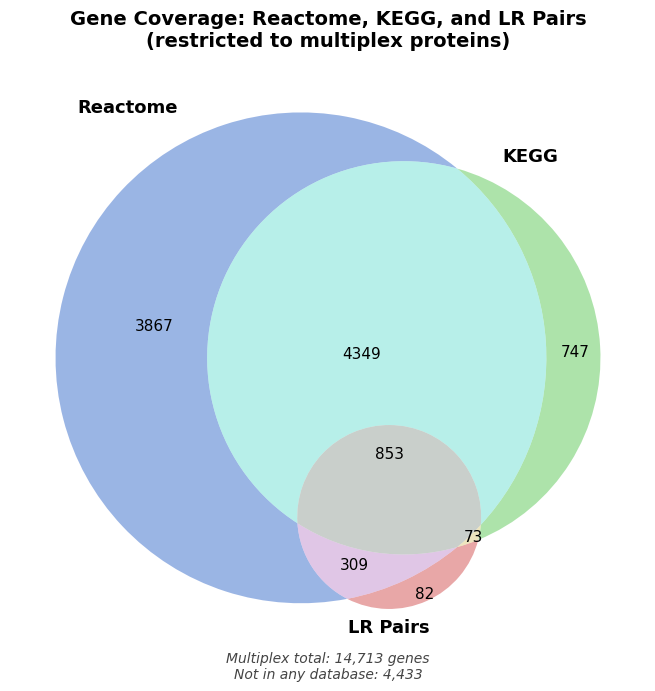

✓ Saved to venn_multiplex_coverage.png


In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib_venn import venn3, venn3_circles
import numpy as np

# ============================================================================
# BUILD SETS (all filtered to multiplex_symbols)
# ============================================================================

# Reactome symbols (filtered to multiplex)
human_reactome = uniprot_pathways_df[
    uniprot_pathways_df['species'] == 'Homo sapiens'
].copy()
human_reactome['gene_symbol'] = (
    human_reactome['uniprot_id']
    .map(uniprot_to_symbol)
    .str.upper()
)
reactome_symbols = (
    set(human_reactome['gene_symbol'].dropna()) & multiplex_symbols
)

# KEGG symbols (filtered to multiplex)
kegg_clean = kegg_pathways_df[
    ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False)
].copy()
kegg_clean['gene_symbol'] = kegg_clean['gene_name_symbol'].str.upper()
kegg_symbols = (
    set(kegg_clean['gene_symbol'].dropna()) & multiplex_symbols
)

# LR symbols (filtered to multiplex)
lr_all_genes_upper = (
    set(lr_pairs['ligand_gname'].str.upper().dropna()) |
    set(lr_pairs['receptor_gname'].str.upper().dropna())
)
lr_symbols = lr_all_genes_upper & multiplex_symbols

print("SET SIZES (multiplex-filtered):")
print(f"  Reactome: {len(reactome_symbols):,}")
print(f"  KEGG:     {len(kegg_symbols):,}")
print(f"  LR pairs: {len(lr_symbols):,}")
print()

# Overlaps
r_only    = reactome_symbols - kegg_symbols - lr_symbols
k_only    = kegg_symbols - reactome_symbols - lr_symbols
lr_only   = lr_symbols - reactome_symbols - kegg_symbols
r_k       = (reactome_symbols & kegg_symbols) - lr_symbols
r_lr      = (reactome_symbols & lr_symbols) - kegg_symbols
k_lr      = (kegg_symbols & lr_symbols) - reactome_symbols
r_k_lr    = reactome_symbols & kegg_symbols & lr_symbols

print("OVERLAPS:")
print(f"  Reactome only:           {len(r_only):,}")
print(f"  KEGG only:               {len(k_only):,}")
print(f"  LR only:                 {len(lr_only):,}")
print(f"  Reactome ∩ KEGG:         {len(r_k):,}")
print(f"  Reactome ∩ LR:           {len(r_lr):,}")
print(f"  KEGG ∩ LR:               {len(k_lr):,}")
print(f"  Reactome ∩ KEGG ∩ LR:   {len(r_k_lr):,}")
print(f"  In multiplex only:       "
      f"{len(multiplex_symbols - reactome_symbols - kegg_symbols - lr_symbols):,}")

# ============================================================================
# PLOT
# ============================================================================

fig, ax = plt.subplots(figsize=(9, 7))

v = venn3(
    subsets=(
        len(r_only),    # Reactome only
        len(k_only),    # KEGG only
        len(r_k),       # Reactome & KEGG
        len(lr_only),   # LR only
        len(r_lr),      # Reactome & LR
        len(k_lr),      # KEGG & LR
        len(r_k_lr),    # all three
    ),
    set_labels=('Reactome', 'KEGG', 'LR Pairs'),
    ax=ax,
    alpha=0.55,
    set_colors=('#4878CF', '#6ACC65', '#D65F5F'),
)

# ── Style the labels ──────────────────────────────────────────────────────────
for label in v.set_labels:
    if label:
        label.set_fontsize(13)
        label.set_fontweight('bold')

for label in v.subset_labels:
    if label:
        label.set_fontsize(11)

# ── Title & subtitle ──────────────────────────────────────────────────────────
ax.set_title(
    'Gene Coverage: Reactome, KEGG, and LR Pairs\n'
    '(restricted to multiplex proteins)',
    fontsize=14,
    fontweight='bold',
    pad=15
)

# ── Annotation: total multiplex, genes not in any DB ─────────────────────────
n_in_none = len(
    multiplex_symbols - reactome_symbols - kegg_symbols - lr_symbols
)
ax.annotate(
    f"Multiplex total: {len(multiplex_symbols):,} genes\n"
    f"Not in any database: {n_in_none:,}",
    xy=(0.5, -0.04),
    xycoords='axes fraction',
    ha='center',
    fontsize=10,
    color='#444444',
    style='italic'
)

plt.tight_layout()
plt.savefig('venn_multiplex_coverage.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved to venn_multiplex_coverage.png")

In [17]:
# ============================================================================
# DIAGNOSE THE DISCREPANCY
# ============================================================================

print("=== WHY THE NUMBERS DIFFER ===\n")

# ── Previous code: UniProt ID direct match ────────────────────────────────────
reactome_uniprot = set(human_reactome['uniprot_id'])
mp_in_reactome_uniprot = multiplex_proteins & reactome_uniprot
print(f"Method 1 (UniProt direct match):")
print(f"  Multiplex proteins in Reactome: {len(mp_in_reactome_uniprot):,}")
print(f"  Sample multiplex proteins: {list(multiplex_proteins)[:5]}")
print(f"  Sample Reactome UniProt IDs: {list(reactome_uniprot)[:5]}")
print()

# ── Venn code: UniProt -> symbol -> match ─────────────────────────────────────
print(f"Method 2 (via gene symbol):")
print(f"  Multiplex proteins mapped to symbol: {len(multiplex_symbols):,} / {len(multiplex_proteins):,}")
print(f"  Multiplex proteins NOT mapped: {len(multiplex_proteins) - len(multiplex_symbols):,}")
print()

# ── The real question: what ARE the multiplex proteins? ──────────────────────
print("=== WHAT FORMAT ARE MULTIPLEX PROTEINS IN? ===\n")

sample_mp = list(multiplex_proteins)[:20]
print(f"Sample multiplex proteins (first 20):")
for p in sample_mp:
    print(f"  '{p}'")
print()

# Check how many look like UniProt IDs vs gene symbols
import re
uniprot_pattern = re.compile(
    r'^[OPQ][0-9][A-Z0-9]{3}[0-9]$'      # reviewed Swiss-Prot
    r'|^[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2}$'  # TrEMBL
)
gene_symbol_pattern = re.compile(r'^[A-Z][A-Z0-9]*$')

n_looks_uniprot = sum(1 for p in multiplex_proteins if uniprot_pattern.match(str(p)))
n_looks_symbol  = sum(1 for p in multiplex_proteins
                      if not uniprot_pattern.match(str(p))
                      and gene_symbol_pattern.match(str(p).upper()))
n_other         = len(multiplex_proteins) - n_looks_uniprot - n_looks_symbol

print(f"Format breakdown of multiplex_proteins:")
print(f"  Looks like UniProt ID:   {n_looks_uniprot:,}")
print(f"  Looks like gene symbol:  {n_looks_symbol:,}")
print(f"  Other format:            {n_other:,}")
print()

# ── Check the symbol mapping itself ──────────────────────────────────────────
print("=== CHECKING uniprot_to_symbol MAPPING ===\n")

# How many multiplex proteins are in the mapping dict?
mp_in_mapping = {p for p in multiplex_proteins if p in uniprot_to_symbol}
mp_not_in_mapping = multiplex_proteins - mp_in_mapping

print(f"Multiplex proteins found in uniprot_to_symbol: {len(mp_in_mapping):,}")
print(f"Multiplex proteins NOT in uniprot_to_symbol:   {len(mp_not_in_mapping):,}")
print()

# Sample of unmapped proteins
print(f"Sample NOT in mapping (first 10):")
for p in list(mp_not_in_mapping)[:10]:
    print(f"  '{p}'")
print()

# ── If multiplex proteins ARE gene symbols, that explains the Venn ────────────
# Check overlap directly as symbols
mp_upper = {str(p).upper() for p in multiplex_proteins}
reactome_sym = set(human_reactome['gene_symbol'].dropna())
kegg_sym = set(kegg_clean['gene_symbol'].dropna())

direct_symbol_reactome = mp_upper & reactome_sym
direct_symbol_kegg     = mp_upper & kegg_sym

print(f"=== IF MULTIPLEX PROTEINS ARE TREATED AS GENE SYMBOLS ===\n")
print(f"  Direct symbol match - Reactome: {len(direct_symbol_reactome):,} / {len(mp_upper):,} "
      f"({100*len(direct_symbol_reactome)/len(mp_upper):.1f}%)")
print(f"  Direct symbol match - KEGG:     {len(direct_symbol_kegg):,} / {len(mp_upper):,} "
      f"({100*len(direct_symbol_kegg)/len(mp_upper):.1f}%)")
print()
print("^^^ If these match the Venn numbers, your multiplex proteins")
print("    are gene symbols, NOT UniProt IDs — the conversion pipeline")
print("    converted them but they were already symbols to begin with.")

=== WHY THE NUMBERS DIFFER ===

Method 1 (UniProt direct match):
  Multiplex proteins in Reactome: 1,218
  Sample multiplex proteins: ['E5RK64', 'A0A024RB15', 'J3KN48', 'A0A7P0TBE2', 'A0A804HJ93']
  Sample Reactome UniProt IDs: ['Q5VXJ0', 'O43451', 'Q86YW0', 'P17677', 'O14936']

Method 2 (via gene symbol):
  Multiplex proteins mapped to symbol: 14,713 / 14,874
  Multiplex proteins NOT mapped: 161

=== WHAT FORMAT ARE MULTIPLEX PROTEINS IN? ===

Sample multiplex proteins (first 20):
  'E5RK64'
  'A0A024RB15'
  'J3KN48'
  'A0A7P0TBE2'
  'A0A804HJ93'
  'C9J9W7'
  'E9PLB0'
  'H7C5S6'
  'C9IZS8'
  'K7ES11'
  'O00635'
  'Q96QR6'
  'J3QL25'
  'Q3SWU9'
  'J3QL99'
  'H0YJI6'
  'H7C3T2'
  'O15095'
  'Q9UHR4'
  'A0A1A7UP97'

Format breakdown of multiplex_proteins:
  Looks like UniProt ID:   14,715
  Looks like gene symbol:  149
  Other format:            10

=== CHECKING uniprot_to_symbol MAPPING ===

Multiplex proteins found in uniprot_to_symbol: 14,713
Multiplex proteins NOT in uniprot_to_symbo

=== DIAGNOSING CANONICAL ID ISSUE ===

Example: your multiplex UniProt IDs vs what's in Reactome
  E5RK64 -> symbol: VAPB -> in Reactome directly: False
  A0A024RB15 -> symbol: RPL41 -> in Reactome directly: False
  J3KN48 -> symbol: ATP6V0E1 -> in Reactome directly: False

Building symbol -> canonical UniProt lookup from Reactome...
  Symbols with canonical Reactome UniProt: 11,319

Multiplex proteins mapped to canonical UniProt: 9,378 / 14,874

Verification examples:
  E5RK64 (VAPB) -> canonical: O95292
  A0A024RB15 (RPL41) -> canonical: P62945
  J3KN48 (ATP6V0E1) -> canonical: O15342
  A0A7P0TBE2 (DLAT) -> canonical: P10515
  A0A804HJ93 (DPM1) -> canonical: O60762

REACTOME COVERAGE (via canonical ID):
  Multiplex proteins in Reactome: 9,378 / 14,874 (63.0%)

KEGG COVERAGE (via canonical ID):
  Multiplex proteins in KEGG: 4,295 / 14,874 (28.9%)

LR PAIR COVERAGE (via gene symbol):
  Multiplex proteins in LR pairs: 1,317 / 14,874 (8.9%)

FINAL SET SIZES FOR VENN (all as gene symbols,

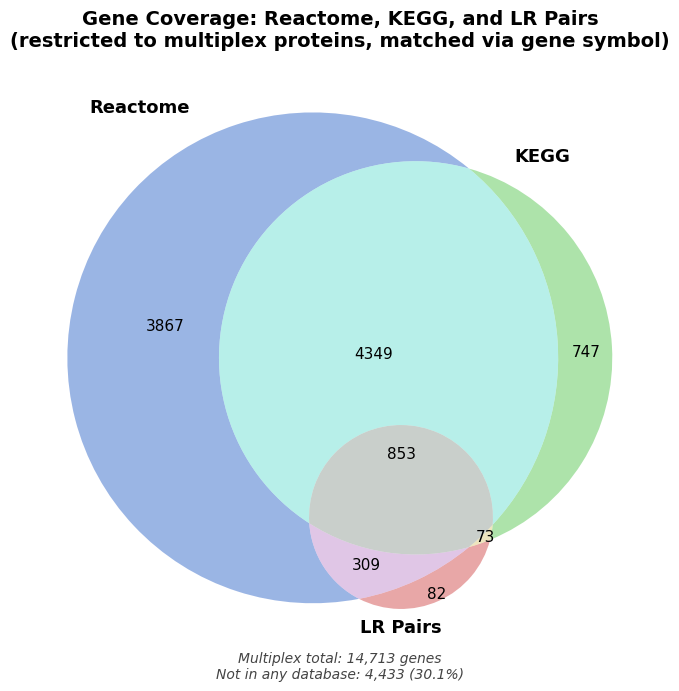

✓ Saved to venn_multiplex_coverage_corrected.png


In [18]:
# ============================================================================
# FIX: MAP MULTIPLEX PROTEINS TO CANONICAL UNIPROT IDs
# ============================================================================
# The problem:
#   E5RK64, A0A024RB15 etc. are isoform/TrEMBL accessions
#   Reactome/KEGG use canonical Swiss-Prot IDs (e.g. P12345, Q9Y287)
#   uniprot_to_symbol maps both, but Reactome only has the canonical ones
#
# Solution: use the gene symbol as a bridge
#   multiplex UniProt -> gene symbol -> canonical UniProt (from Reactome/KEGG)

print("=== DIAGNOSING CANONICAL ID ISSUE ===\n")

# Step 1: Show the problem clearly
sample_mp = ['E5RK64', 'A0A024RB15', 'J3KN48']
print("Example: your multiplex UniProt IDs vs what's in Reactome")
for uid in sample_mp:
    symbol = uniprot_to_symbol.get(uid, 'NOT FOUND')
    in_reactome = uid in reactome_uniprot
    print(f"  {uid} -> symbol: {symbol} -> in Reactome directly: {in_reactome}")

print()

# Step 2: Build symbol -> canonical UniProt mapping from Reactome itself
# Reactome only contains canonical IDs so we can reverse it
print("Building symbol -> canonical UniProt lookup from Reactome...")
reactome_symbol_to_uniprot = {}
for uid, symbol in uniprot_to_symbol.items():
    if uid in reactome_uniprot:  # only keep canonical IDs (ones Reactome knows)
        sym_upper = symbol.upper()
        if sym_upper not in reactome_symbol_to_uniprot:
            reactome_symbol_to_uniprot[sym_upper] = uid

print(f"  Symbols with canonical Reactome UniProt: {len(reactome_symbol_to_uniprot):,}")
print()

# Step 3: For each multiplex protein, find its canonical ID via symbol bridge
mp_to_canonical = {}  # {original_uid: canonical_uid}
for uid in multiplex_proteins:
    symbol = uniprot_to_symbol.get(uid)
    if symbol:
        canonical = reactome_symbol_to_uniprot.get(symbol.upper())
        if canonical:
            mp_to_canonical[uid] = canonical

print(f"Multiplex proteins mapped to canonical UniProt: {len(mp_to_canonical):,} / {len(multiplex_proteins):,}")
print()

# Step 4: Check a few to verify
print("Verification examples:")
for uid in list(mp_to_canonical.items())[:5]:
    orig, canon = uid
    symbol = uniprot_to_symbol.get(orig, '?')
    print(f"  {orig} ({symbol}) -> canonical: {canon}")
print()

# ============================================================================
# RECOMPUTE COVERAGE USING CANONICAL IDS
# ============================================================================

canonical_set = set(mp_to_canonical.values())

# Reactome
mp_in_reactome_canonical = canonical_set & reactome_uniprot
print(f"REACTOME COVERAGE (via canonical ID):")
print(f"  Multiplex proteins in Reactome: {len(mp_in_reactome_canonical):,} / {len(multiplex_proteins):,} "
      f"({100*len(mp_in_reactome_canonical)/len(multiplex_proteins):.1f}%)")
print()

# KEGG - same approach but using KEGG's uniprot IDs
kegg_uniprot_set = set(
    kegg_pathways_df.loc[
        ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False),
        'gene_name_uniprot'
    ]
)
mp_in_kegg_canonical = canonical_set & kegg_uniprot_set
print(f"KEGG COVERAGE (via canonical ID):")
print(f"  Multiplex proteins in KEGG: {len(mp_in_kegg_canonical):,} / {len(multiplex_proteins):,} "
      f"({100*len(mp_in_kegg_canonical)/len(multiplex_proteins):.1f}%)")
print()

# LR pairs
lr_all_symbols = (
    set(lr_pairs['ligand_gname'].str.upper().dropna()) |
    set(lr_pairs['receptor_gname'].str.upper().dropna())
)
# Map multiplex symbols to check against LR
multiplex_symbol_set = {
    uniprot_to_symbol[p].upper()
    for p in multiplex_proteins
    if p in uniprot_to_symbol
}
mp_in_lr = multiplex_symbol_set & lr_all_symbols
print(f"LR PAIR COVERAGE (via gene symbol):")
print(f"  Multiplex proteins in LR pairs: {len(mp_in_lr):,} / {len(multiplex_proteins):,} "
      f"({100*len(mp_in_lr)/len(multiplex_proteins):.1f}%)")
print()

# ============================================================================
# UPDATED VENN DIAGRAM
# ============================================================================

# All three sets as gene symbols (the common currency that works)
# Reactome: symbols of multiplex proteins that have a canonical Reactome entry
reactome_mp_symbols = {
    uniprot_to_symbol[uid].upper()
    for uid in multiplex_proteins
    if uid in uniprot_to_symbol
    and uniprot_to_symbol[uid].upper() in reactome_symbol_to_uniprot
}

# KEGG: symbols of multiplex proteins in KEGG
kegg_symbol_to_check = set(kegg_clean['gene_symbol'].dropna())
kegg_mp_symbols = multiplex_symbol_set & kegg_symbol_to_check

# LR: already computed above
lr_mp_symbols = mp_in_lr

print(f"FINAL SET SIZES FOR VENN (all as gene symbols, filtered to multiplex):")
print(f"  Reactome: {len(reactome_mp_symbols):,}")
print(f"  KEGG:     {len(kegg_mp_symbols):,}")
print(f"  LR pairs: {len(lr_mp_symbols):,}")
print()

# Overlaps
r_only  = reactome_mp_symbols - kegg_mp_symbols - lr_mp_symbols
k_only  = kegg_mp_symbols - reactome_mp_symbols - lr_mp_symbols
lr_only = lr_mp_symbols - reactome_mp_symbols - kegg_mp_symbols
r_k     = (reactome_mp_symbols & kegg_mp_symbols) - lr_mp_symbols
r_lr    = (reactome_mp_symbols & lr_mp_symbols) - kegg_mp_symbols
k_lr    = (kegg_mp_symbols & lr_mp_symbols) - reactome_mp_symbols
r_k_lr  = reactome_mp_symbols & kegg_mp_symbols & lr_mp_symbols
in_none = multiplex_symbol_set - reactome_mp_symbols - kegg_mp_symbols - lr_mp_symbols

print(f"OVERLAPS:")
print(f"  Reactome only:         {len(r_only):,}")
print(f"  KEGG only:             {len(k_only):,}")
print(f"  LR only:               {len(lr_only):,}")
print(f"  Reactome ∩ KEGG:       {len(r_k):,}")
print(f"  Reactome ∩ LR:         {len(r_lr):,}")
print(f"  KEGG ∩ LR:             {len(k_lr):,}")
print(f"  All three:             {len(r_k_lr):,}")
print(f"  In none:               {len(in_none):,} "
      f"({100*len(in_none)/len(multiplex_symbol_set):.1f}%)")
print()

# ── Plot ──────────────────────────────────────────────────────────────────────
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

v = venn3(
    subsets=(
        len(r_only),
        len(k_only),
        len(r_k),
        len(lr_only),
        len(r_lr),
        len(k_lr),
        len(r_k_lr),
    ),
    set_labels=('Reactome', 'KEGG', 'LR Pairs'),
    ax=ax,
    alpha=0.55,
    set_colors=('#4878CF', '#6ACC65', '#D65F5F'),
)

for label in v.set_labels:
    if label:
        label.set_fontsize(13)
        label.set_fontweight('bold')

for label in v.subset_labels:
    if label:
        label.set_fontsize(11)

ax.set_title(
    'Gene Coverage: Reactome, KEGG, and LR Pairs\n'
    '(restricted to multiplex proteins, matched via gene symbol)',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.annotate(
    f"Multiplex total: {len(multiplex_symbol_set):,} genes\n"
    f"Not in any database: {len(in_none):,} "
    f"({100*len(in_none)/len(multiplex_symbol_set):.1f}%)",
    xy=(0.5, -0.04),
    xycoords='axes fraction',
    ha='center',
    fontsize=10,
    color='#444444',
    style='italic'
)

plt.tight_layout()
plt.savefig('venn_multiplex_coverage_corrected.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved to venn_multiplex_coverage_corrected.png")